In [1]:
from req_functions_from_ApproxSP import *
import pandas as pd
import ast 

In [2]:
## Two for One Code

import itertools
import copy

def generate_sw_manipulations(w_pref):
    """
    Sw: Move any two distinct men to top of w's list in any order.
    """
    manipulations = []
    for mi, mj in itertools.permutations(w_pref, 2): 
        rest = [m for m in w_pref if m != mi and m != mj]
        new_pref = [mi, mj] + rest
        manipulations.append(new_pref)
    return manipulations


def generate_sm_manipulations(m_pref, mu_m):
    """
    Sm: Promote µ(m) to top, then for every other woman, promote her to top of that list.
    """
    sm = []
    bm = [mu_m] + [w for w in m_pref if w != mu_m]
    sm.append(bm)

    for w0 in bm[1:]:  # exclude mu(m) which is already at the top
        manipulated = [w0] + [w for w in bm if w != w0]
        sm.append(manipulated)

    return sm


def two_for_one(mpref, wpref, accomplice, beneficiary, initial_matching):
    #initial_matching = gale_shapley(mpref, wpref)
    mpref_prime = copy.deepcopy(mpref)
    wpref_prime = copy.deepcopy(wpref)
    best_matching = initial_matching

    accomplice_pref = mpref[accomplice - 1] 
    beneficiary_pref = wpref[beneficiary - 1]

    Sw = generate_sw_manipulations(beneficiary_pref)

    for w_misreport in Sw:
        #t5 = time.perf_counter()

        Sm = generate_sm_manipulations(accomplice_pref, initial_matching[accomplice - 1])

        for m_misreport in Sm:
            #t6 = time.perf_counter()
            mpref_prime[accomplice - 1] = m_misreport 
            wpref_prime[beneficiary - 1] = w_misreport
            new_matching = gale_shapley(mpref_prime, wpref_prime)

            new_w_pairing = new_matching[beneficiary - 1]
            new_m_pairing = new_matching[accomplice - 1]

            if beneficiary_pref.index(new_w_pairing) < beneficiary_pref.index(best_matching[beneficiary - 1]) and best_matching[accomplice - 1] == new_m_pairing:
                best_matching = new_matching
                accomplice_pref = m_misreport
                beneficiary_pref = w_misreport
        #t7 = time.perf_counter()
        #print(f"Time for t5 - t6: {t6 - t5:.4f} seconds")
        #print(f"Time for t6 - t7: {t7 - t6:.4f} seconds")
    return best_matching, accomplice_pref, beneficiary_pref

**Mallows**

In [3]:
df = pd.read_csv("mallows_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_gain.csv', index=False)


3600it [3:26:43,  3.45s/it] 


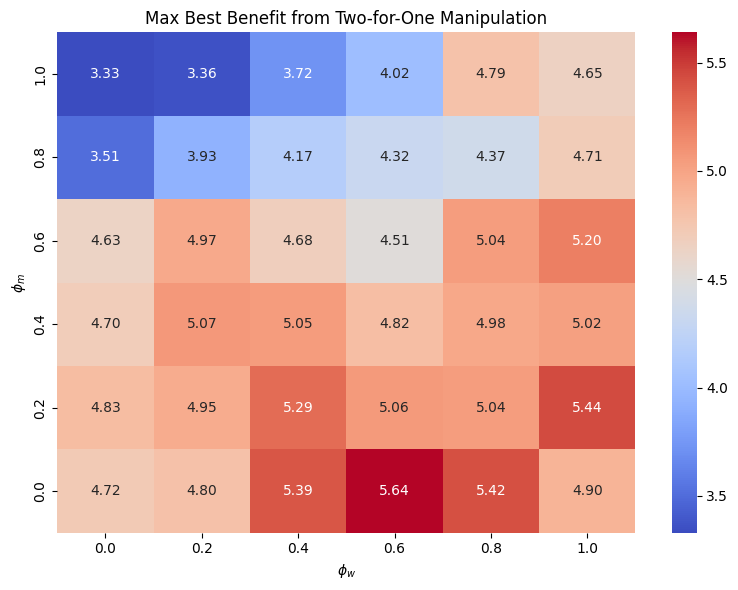

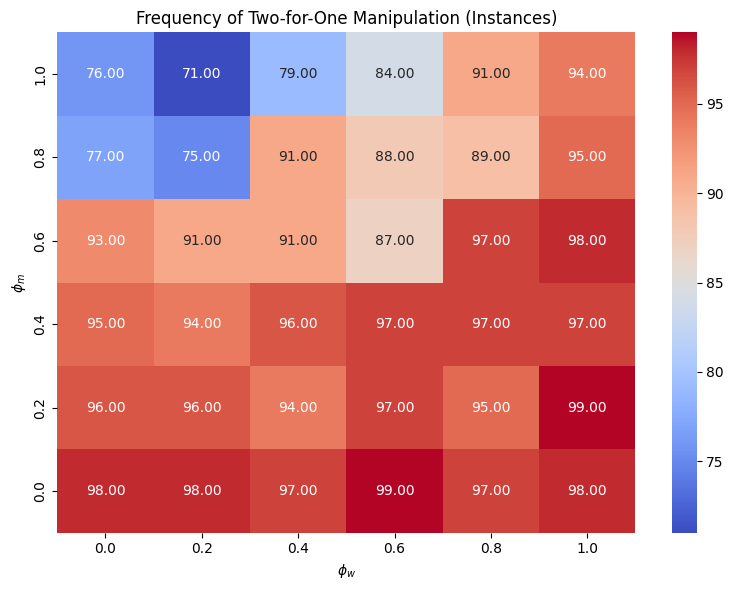

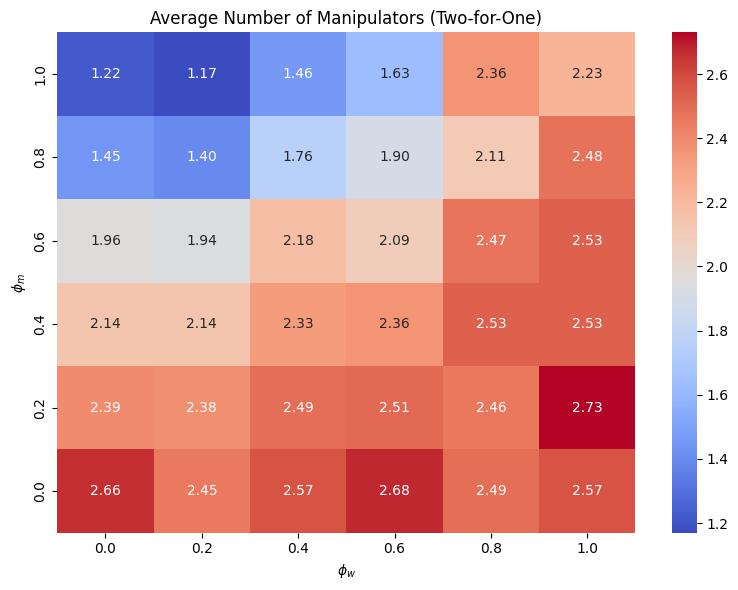

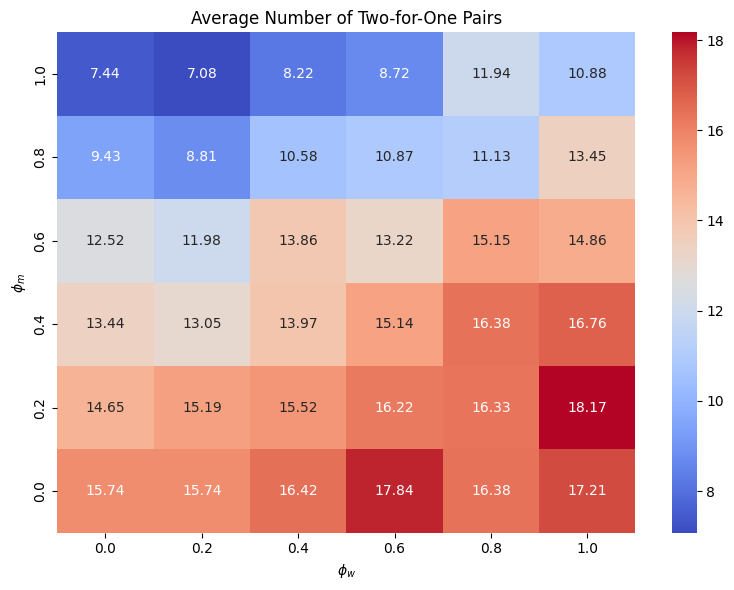

In [48]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)
    
    
    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_two", "Max Best Benefit from Two-for-One Manipulation", "mallows_max_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "mallows_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "mallows_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "mallows_number_two_pairs")


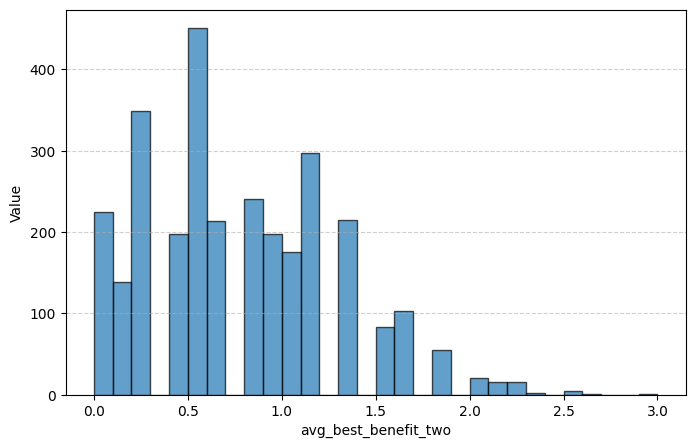

avg_best_benefit_two mean: 0.7595
avg_best_benefit_two median: 0.7000
avg_best_benefit_two max: 3.0000


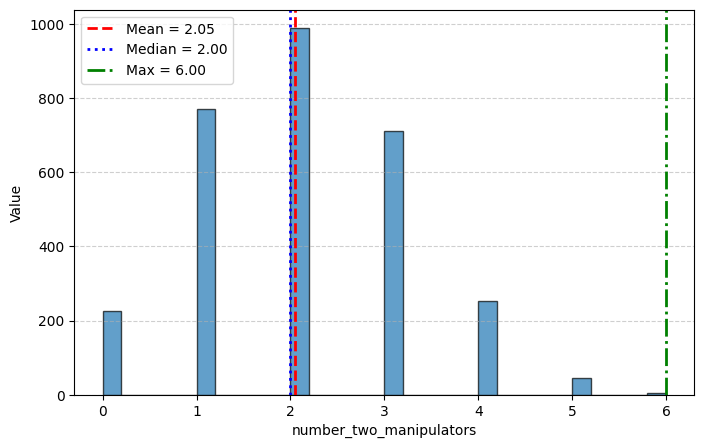

Mean of number_two_manipulators: 2.0507
Median of number_two_manipulators: 2.0000
Max of number_two_manipulators: 6.0000


In [8]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("CSV_Files/expectations_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

#df = df[df["avg_best_benefit_two"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["avg_best_benefit_two"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("avg_best_benefit_two")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["avg_best_benefit_two"].mean()

median_val = df["avg_best_benefit_two"].median()

max_val = df["avg_best_benefit_two"].max()
 
print(f"avg_best_benefit_two mean: {mean_val:.4f}")

print(f"avg_best_benefit_two median: {median_val:.4f}")

print(f"avg_best_benefit_two max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("CSV_Files/expectations_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

#positive_df = df[df["number_two_manipulators"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(df["number_two_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("number_two_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = df["number_two_manipulators"].mean()

median_pos = df["number_two_manipulators"].median()

max_pos = df["number_two_manipulators"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of number_two_manipulators: {mean_pos:.4f}")

print(f"Median of number_two_manipulators: {median_pos:.4f}")

print(f"Max of number_two_manipulators: {max_pos:.4f}")

 

**Mallows MD**

In [5]:
df = pd.read_csv("mallows_MD_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_MD_gain.csv', index=False)


3600it [51:31,  1.16it/s] 


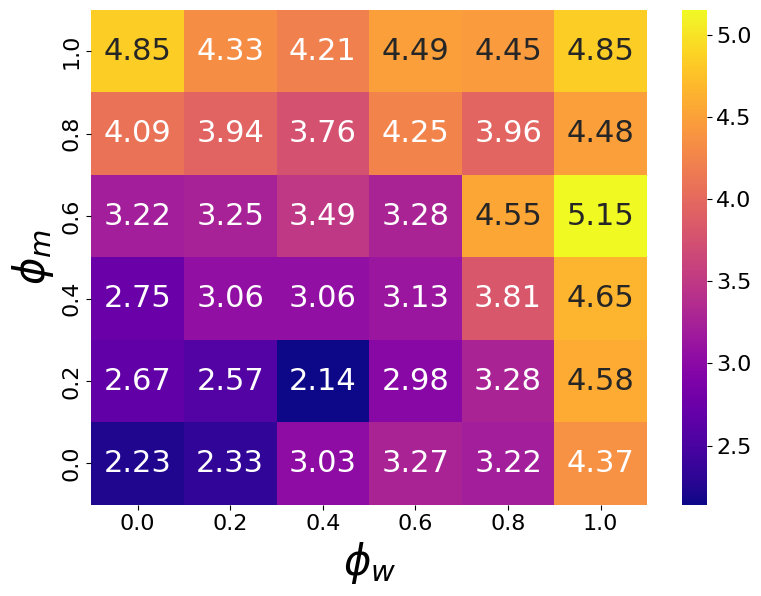

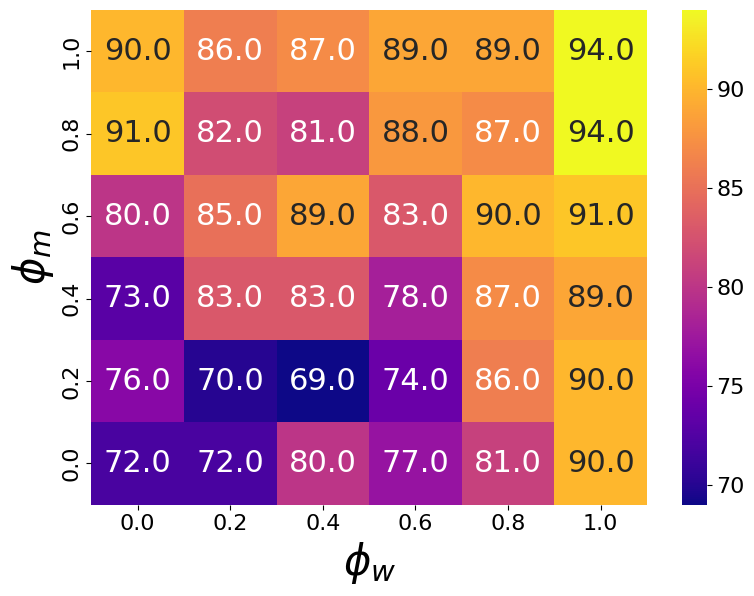

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_euclidean_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22})
    #plt.title(title)
    plt.xlabel(r'$\phi_w$', fontsize = 30)
    plt.ylabel(r"$\phi_m$", fontsize = 30)
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)
 
    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )
    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".1f", cmap="plasma", annot_kws={"size": 22})
    #plt.title(title)
    plt.xlabel(r'$\phi_w$', fontsize = 30)
    plt.ylabel(r"$\phi_m$", fontsize = 30)
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)
 
    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_two", "Average Best Benefit from Two-for-One Manipulation", "mallows_euclidean_max_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "mallows_euclidean_two_freq_instance")
#plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "mallows_MD_number_two_manipulators")
#plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "mallows_MD_number_two_pairs")


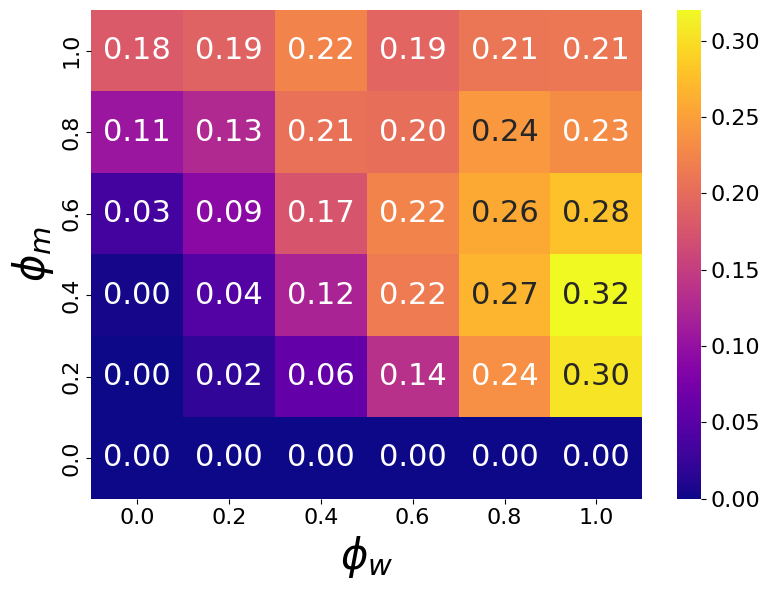

In [52]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MA_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_two_manipulators"].mean().reset_index()

heatmap_data["number_two_manipulators"] = heatmap_data["number_two_manipulators"] / 10  # Scale here

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_two_manipulators")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_MA_number_two_manipulators.pdf", format="pdf")
plt.show()


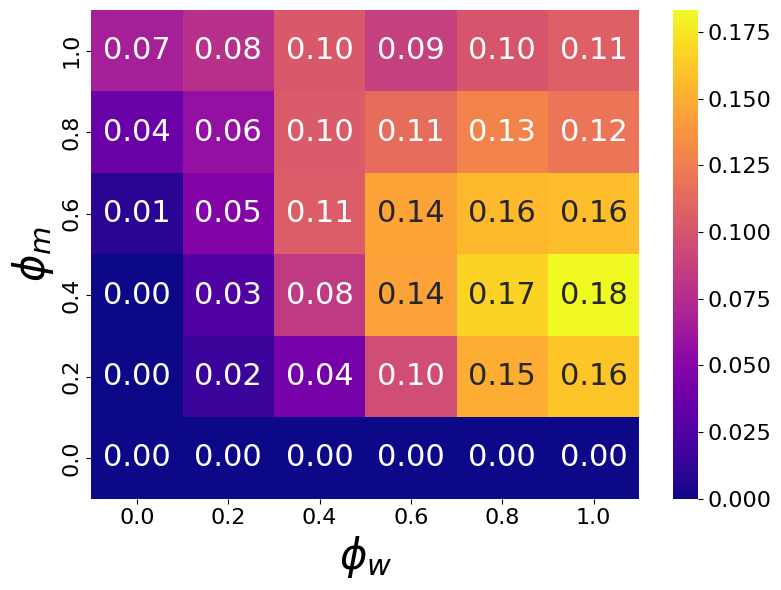

In [53]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MA_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_two_pairs"].mean().reset_index()

heatmap_data["number_two_pairs"] = heatmap_data["number_two_pairs"] / 100  # Scale here

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_two_pairs")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_MA_number_two_pairs.pdf", format="pdf")
plt.show()


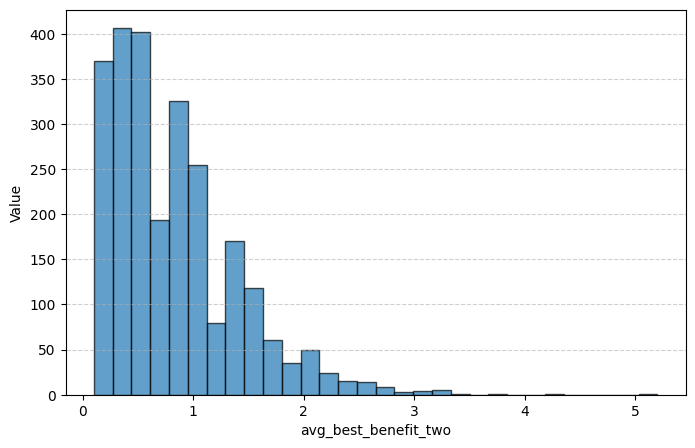

avg_best_benefit_two mean: 0.8169
avg_best_benefit_two median: 0.7000
avg_best_benefit_two max: 5.2000


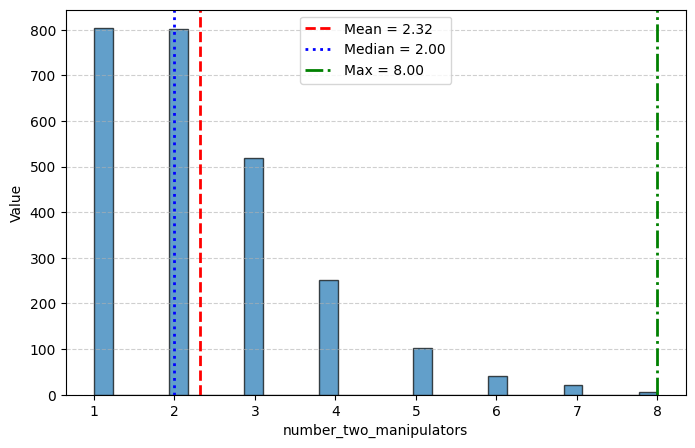

Mean of number_two_manipulators: 2.3235
Median of number_two_manipulators: 2.0000
Max of number_two_manipulators: 8.0000


In [6]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["avg_best_benefit_two"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["avg_best_benefit_two"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("avg_best_benefit_two")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["avg_best_benefit_two"].mean()

median_val = df["avg_best_benefit_two"].median()

max_val = df["avg_best_benefit_two"].max()
 
print(f"avg_best_benefit_two mean: {mean_val:.4f}")

print(f"avg_best_benefit_two median: {median_val:.4f}")

print(f"avg_best_benefit_two max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MD_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["number_two_manipulators"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["number_two_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("number_two_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["number_two_manipulators"].mean()

median_pos = positive_df["number_two_manipulators"].median()

max_pos = positive_df["number_two_manipulators"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of number_two_manipulators: {mean_pos:.4f}")

print(f"Median of number_two_manipulators: {median_pos:.4f}")

print(f"Max of number_two_manipulators: {max_pos:.4f}")

 

**Mallows MA**

In [50]:
df = pd.read_csv("mallows_MA_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_MA_gain.csv', index=False)


3600it [32:29,  1.85it/s]


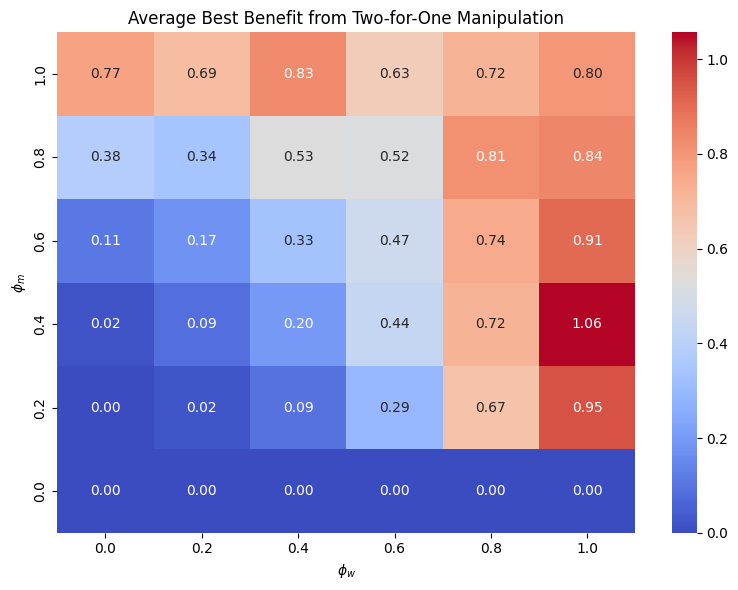

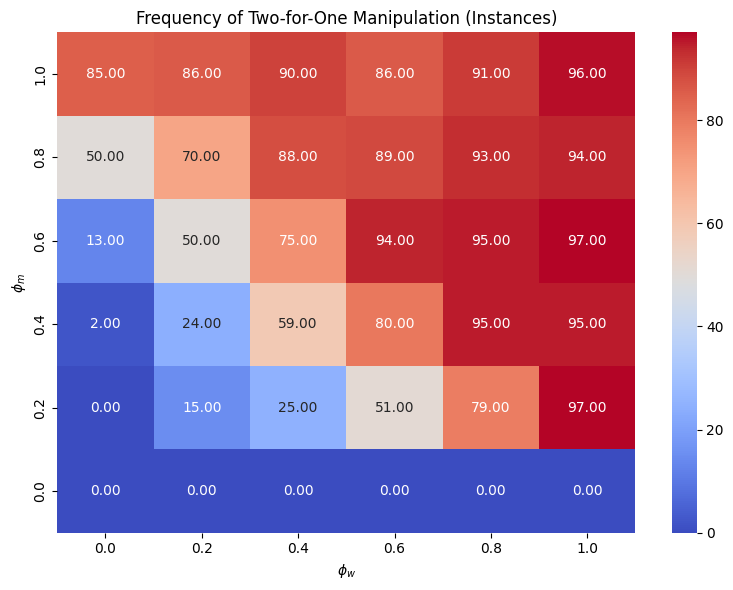

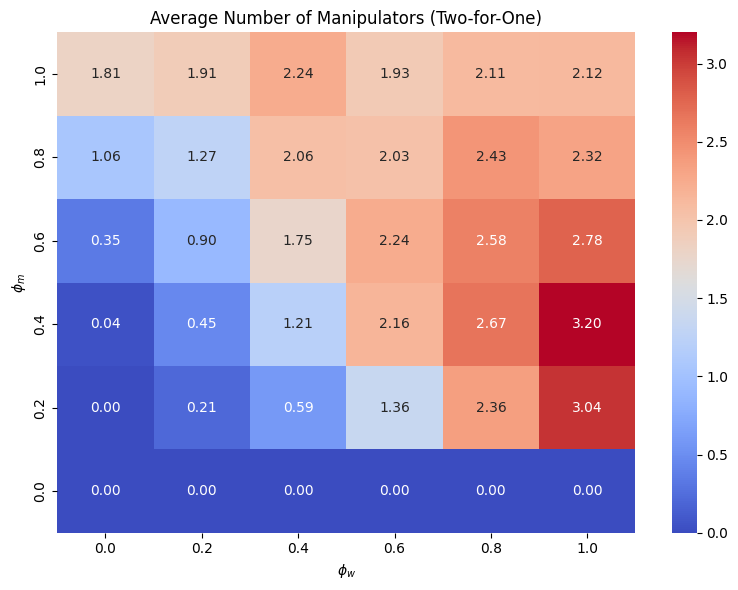

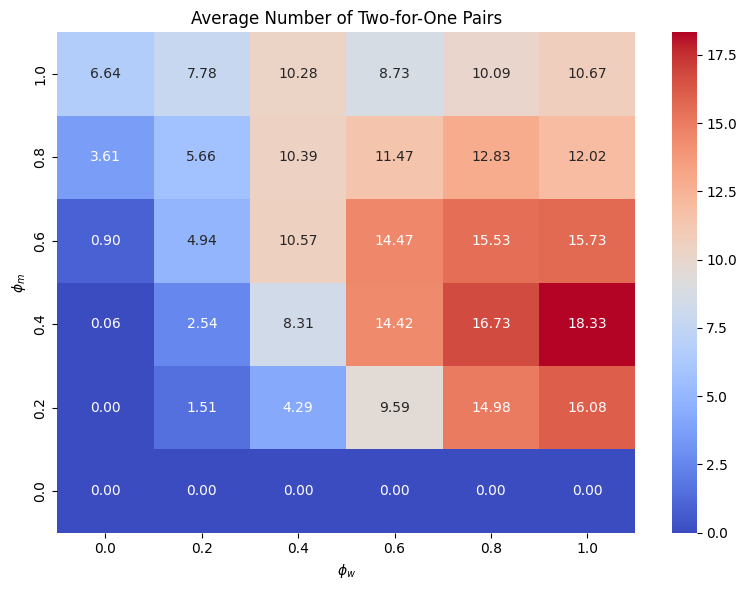

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("mallows_MA_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []
avg_best_benefit_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    avg_val = np.mean(best_benefits_per_woman)
    avg_best_benefit_list.append(avg_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list
df["avg_best_benefit_two"] = avg_best_benefit_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("mallows_MA_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()
 
    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["phi_m", "phi_w"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="phi_m",
        columns="phi_w",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel(r'$\phi_w$')
    plt.ylabel(r"$\phi_m$")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "avg_best_benefit_two", "Average Best Benefit from Two-for-One Manipulation", "mallows_MA_avg_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "mallows_MA_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "mallows_MA_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "mallows_MA_number_two_pairs")


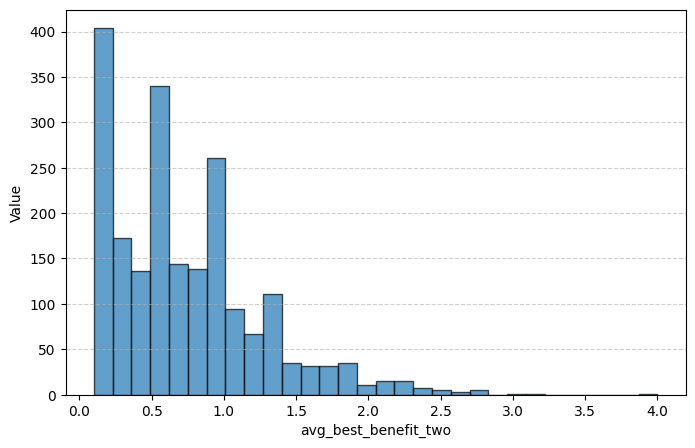

avg_best_benefit_two mean: 0.7342
avg_best_benefit_two median: 0.6000
avg_best_benefit_two max: 4.0000


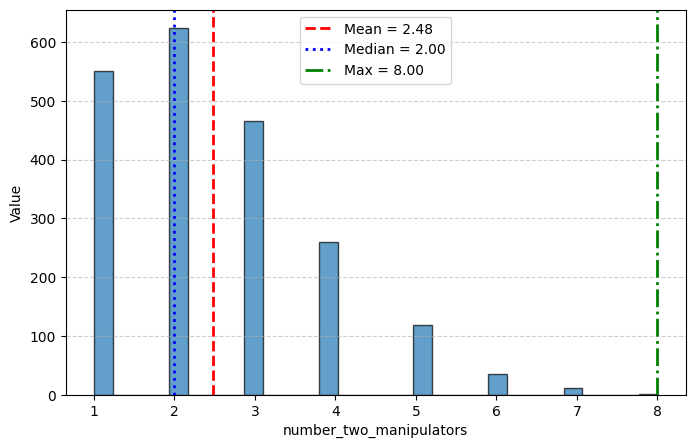

Mean of number_two_manipulators: 2.4797
Median of number_two_manipulators: 2.0000
Max of number_two_manipulators: 8.0000


In [5]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["avg_best_benefit_two"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["avg_best_benefit_two"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("avg_best_benefit_two")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["avg_best_benefit_two"].mean()

median_val = df["avg_best_benefit_two"].median()

max_val = df["avg_best_benefit_two"].max()
 
print(f"avg_best_benefit_two mean: {mean_val:.4f}")

print(f"avg_best_benefit_two median: {median_val:.4f}")

print(f"avg_best_benefit_two max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_MA_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["number_two_manipulators"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["number_two_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("number_two_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["number_two_manipulators"].mean()

median_pos = positive_df["number_two_manipulators"].median()

max_pos = positive_df["number_two_manipulators"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of number_two_manipulators: {mean_pos:.4f}")

print(f"Median of number_two_manipulators: {median_pos:.4f}")

print(f"Max of number_two_manipulators: {max_pos:.4f}")

 

**Mallows Euclidean**

In [7]:
df = pd.read_csv("mallows_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_euclidean_gain.csv', index=False)


3600it [38:20,  1.56it/s]


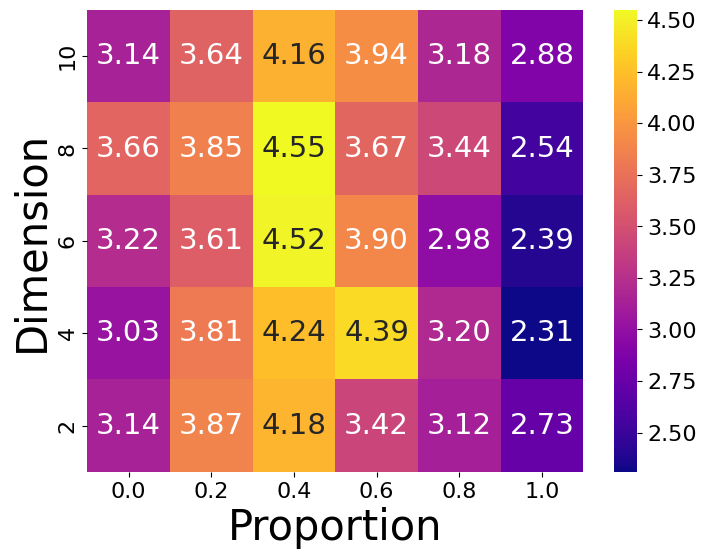

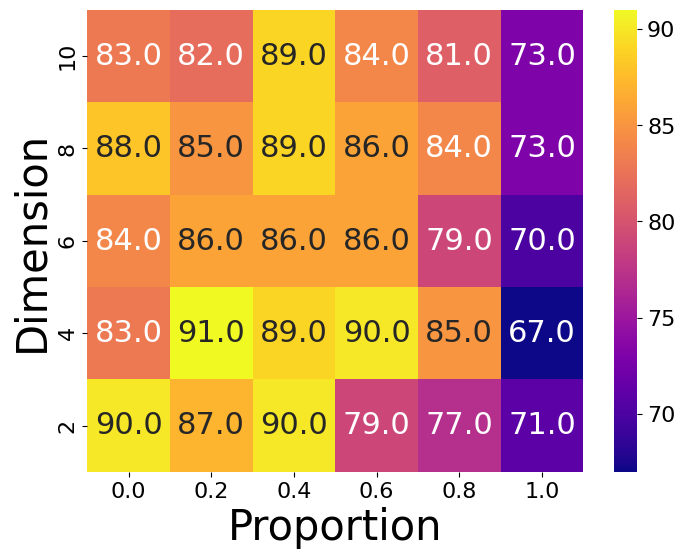

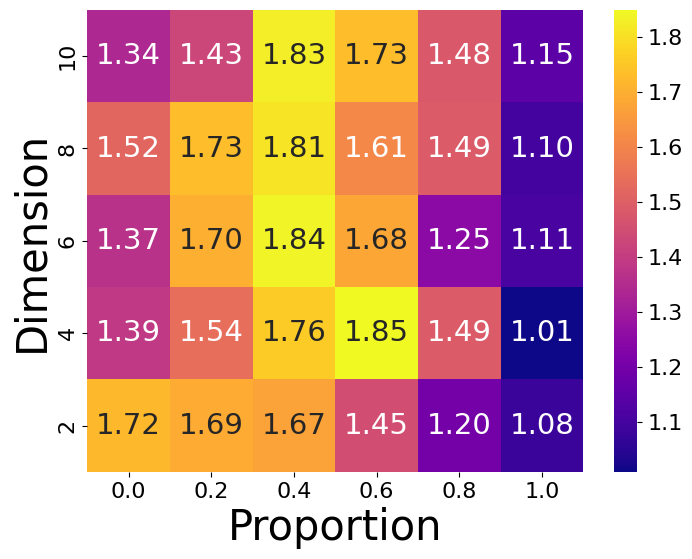

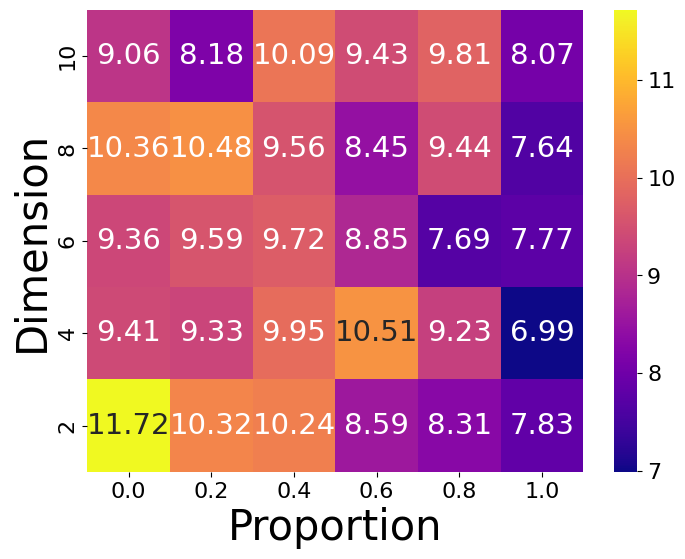

In [59]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("reverse_euclidean_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("reverse_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "proportion"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="proportion",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 21}
    )
    #plt.title("Mallows MA")
    plt.xlabel("Proportion", fontsize = 30)
    plt.ylabel("Dimension", fontsize=30)
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "proportion"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="proportion",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".1f", cmap="plasma", annot_kws={"size": 22}
    )
    #plt.title("Mallows MA")
    plt.xlabel("Proportion", fontsize = 30)
    plt.ylabel("Dimension", fontsize=30)
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_two", "Max Best Benefit from Two-for-One Manipulation", "reverse_euclidean_max_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "mallows_euclidean_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "mallows_euclidean_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "mallows_euclidean_number_two_pairs")



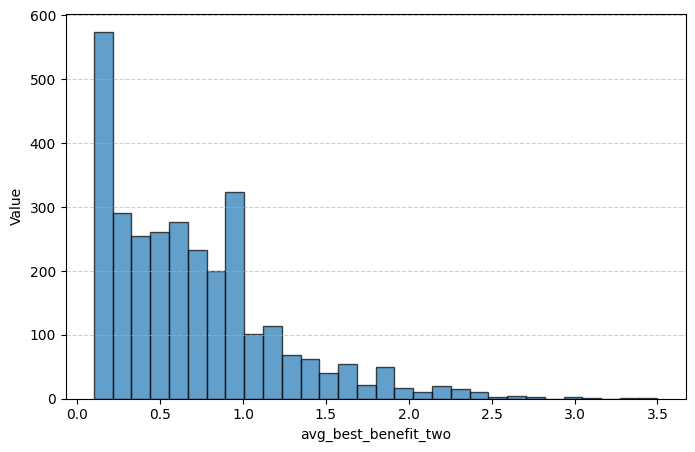

avg_best_benefit_two mean: 0.6963
avg_best_benefit_two median: 0.6000
avg_best_benefit_two max: 3.5000


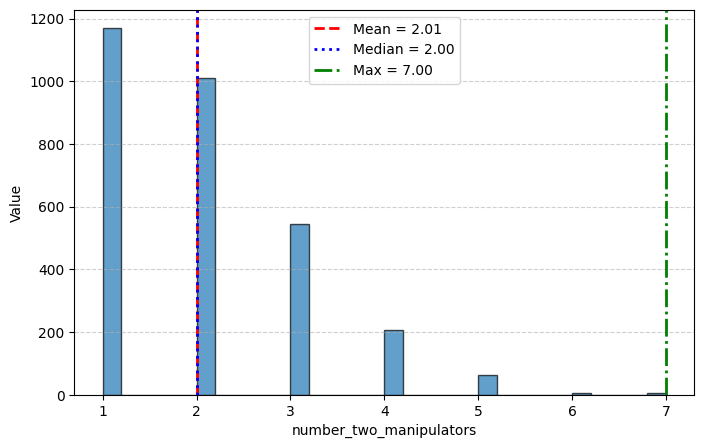

Mean of number_two_manipulators: 2.0090
Median of number_two_manipulators: 2.0000
Max of number_two_manipulators: 7.0000


In [4]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["avg_best_benefit_two"] > 0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["avg_best_benefit_two"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("avg_best_benefit_two")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["avg_best_benefit_two"].mean()

median_val = df["avg_best_benefit_two"].median()

max_val = df["avg_best_benefit_two"].max()
 
print(f"avg_best_benefit_two mean: {mean_val:.4f}")

print(f"avg_best_benefit_two median: {median_val:.4f}")

print(f"avg_best_benefit_two max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["number_two_manipulators"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["number_two_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("number_two_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["number_two_manipulators"].mean()

median_pos = positive_df["number_two_manipulators"].median()

max_pos = positive_df["number_two_manipulators"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of number_two_manipulators: {mean_pos:.4f}")

print(f"Median of number_two_manipulators: {median_pos:.4f}")

print(f"Max of number_two_manipulators: {max_pos:.4f}")

 

**Reverse Euclidean**

In [10]:
df = pd.read_csv("reverse_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matching"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('reverse_euclidean_gain.csv', index=False)


3000it [41:39,  1.20it/s]


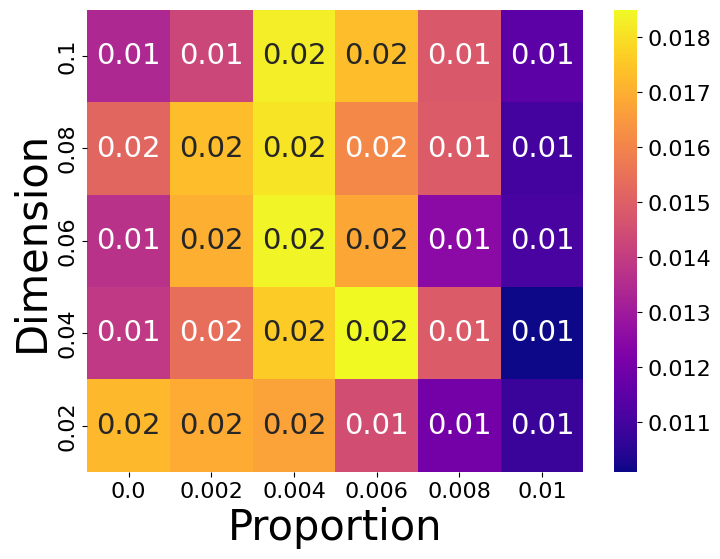

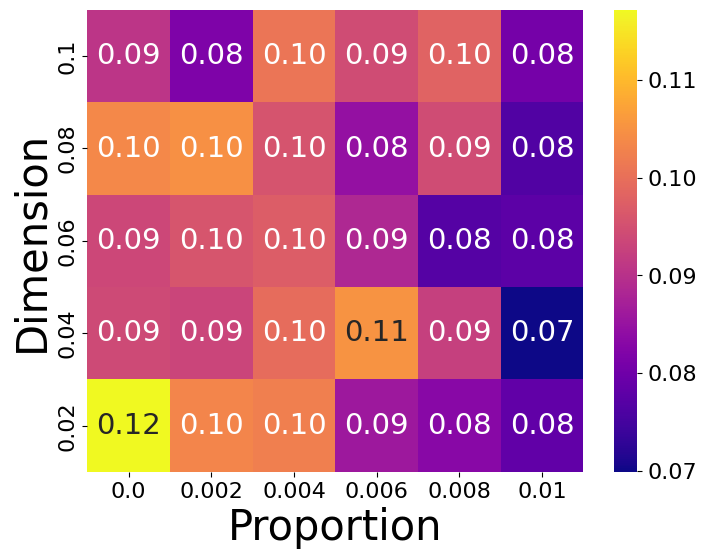

In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("reverse_euclidean_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman)
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("reverse_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "proportion"])[value_col].mean().reset_index()

    heatmap_df = heatmap_df / 100

    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="proportion",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 21}
    )
    #plt.title("Mallows MA")
    plt.xlabel("Proportion", fontsize = 30)
    plt.ylabel("Dimension", fontsize=30)
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "proportion"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="proportion",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    ax = sns.heatmap(heatmap_matrix, annot=True, fmt=".1f", cmap="plasma", annot_kws={"size": 22}
    )
    #plt.title("Mallows MA")
    plt.xlabel("Proportion", fontsize = 30)
    plt.ylabel("Dimension", fontsize=30)
    plt.gca().invert_yaxis()

    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    colorbar = ax.collections[0].colorbar
    colorbar.ax.tick_params(labelsize=16)

    #plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()


# --- Generate the 4 plots ---
#plot_heatmap(df, "max_best_benefit_two", "Max Best Benefit from Two-for-One Manipulation", "reverse_euclidean_avg_best_benefit_two")
#plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "reverse_euclidean_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "reverse_euclidean_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "reverse_euclidean_number_two_pairs")



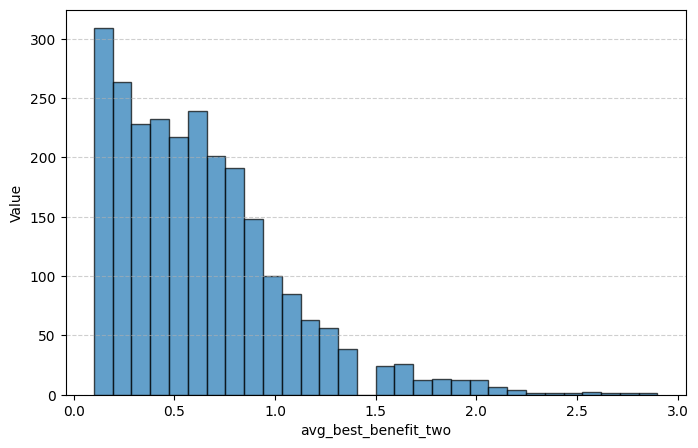

avg_best_benefit_two mean: 0.6147
avg_best_benefit_two median: 0.5000
avg_best_benefit_two max: 2.9000


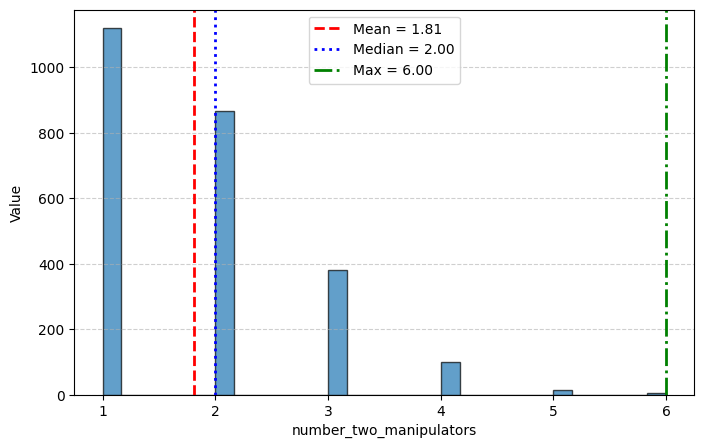

Mean of number_two_manipulators: 1.8102
Median of number_two_manipulators: 2.0000
Max of number_two_manipulators: 6.0000


In [3]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["avg_best_benefit_two"] >0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["avg_best_benefit_two"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("avg_best_benefit_two")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["avg_best_benefit_two"].mean()

median_val = df["avg_best_benefit_two"].median()

max_val = df["avg_best_benefit_two"].max()
 
print(f"avg_best_benefit_two mean: {mean_val:.4f}")

print(f"avg_best_benefit_two median: {median_val:.4f}")

print(f"avg_best_benefit_two max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("reverse_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["number_two_manipulators"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["number_two_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("number_two_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["number_two_manipulators"].mean()

median_pos = positive_df["number_two_manipulators"].median()

max_pos = positive_df["number_two_manipulators"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of number_two_manipulators: {mean_pos:.4f}")

print(f"Median of number_two_manipulators: {median_pos:.4f}")

print(f"Max of number_two_manipulators: {max_pos:.4f}")

 

**Expectations Euclidean**

In [12]:
df = pd.read_csv("expectations_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matching"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('expectations_euclidean_gain.csv', index=False)


3000it [4:01:49,  4.84s/it] 


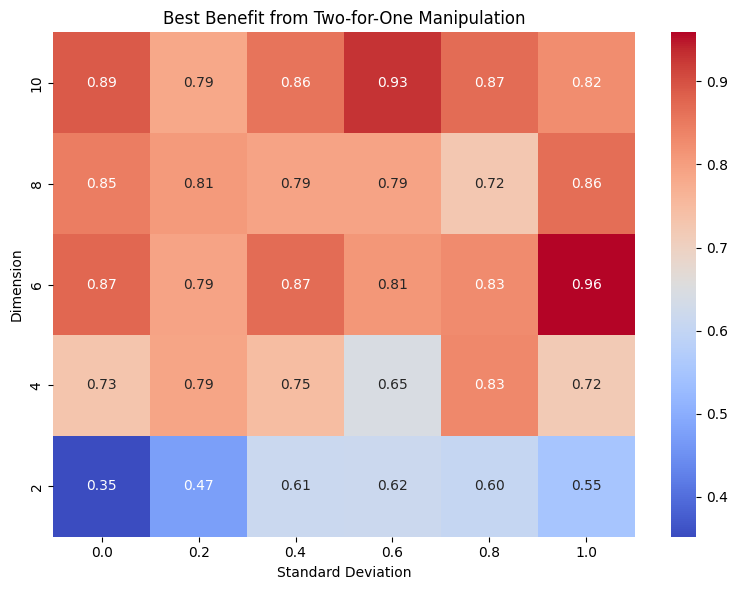

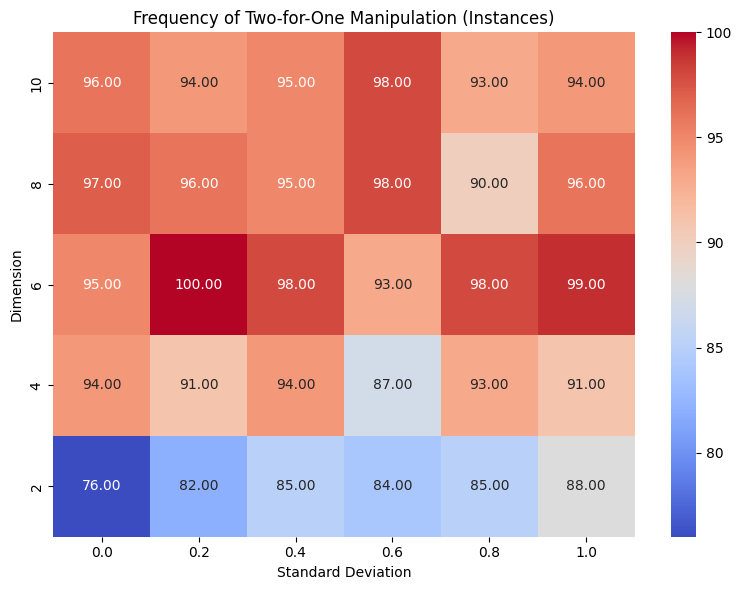

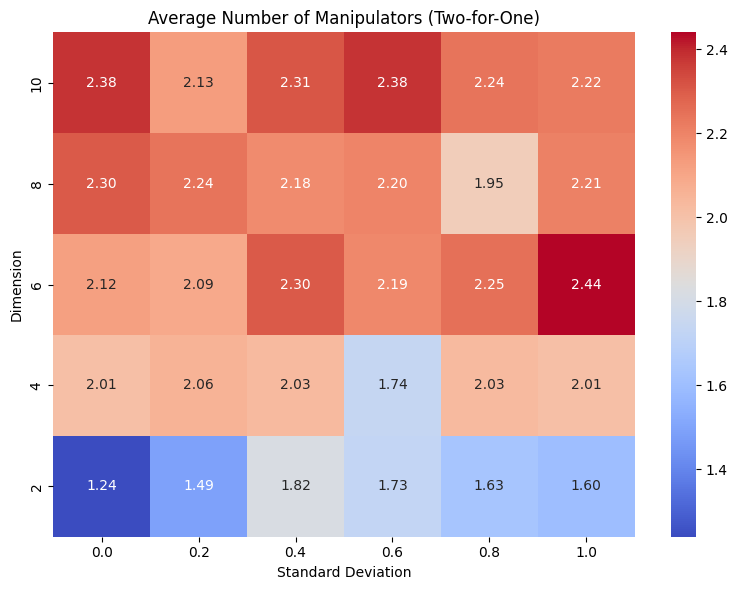

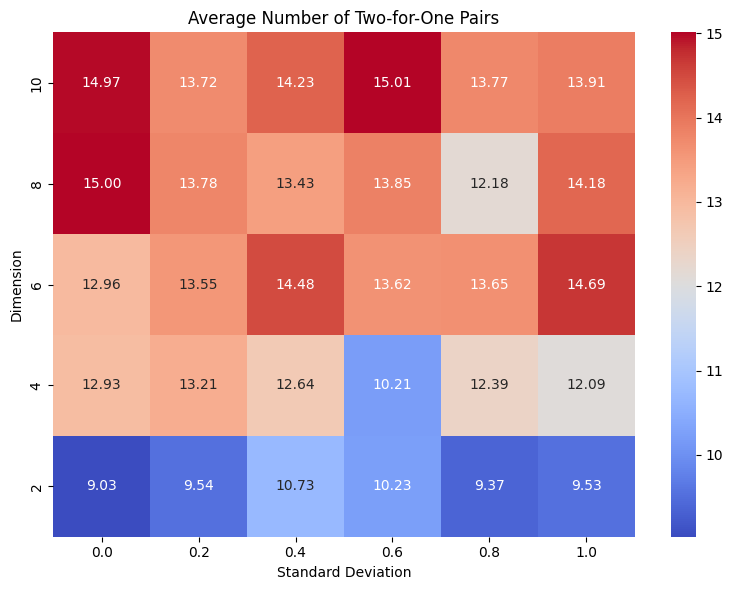

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("expectations_euclidean_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []
avg_best_benefit_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    avg_val = np.mean(best_benefits_per_woman) #change np.mean to np.max
    avg_best_benefit_list.append(avg_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if avg_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["avg_best_benefit_two"] = avg_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("expectations_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "std"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="std",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Standard Deviation")
    plt.ylabel("Dimension")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "std"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="std",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Standard Deviation")
    plt.ylabel("Dimension")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "avg_best_benefit_two", "Best Benefit from Two-for-One Manipulation", "expectations_euclidean_max_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "expectations_euclidean_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "expectations_euclidean_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "expectations_euclidean_number_two_pairs")



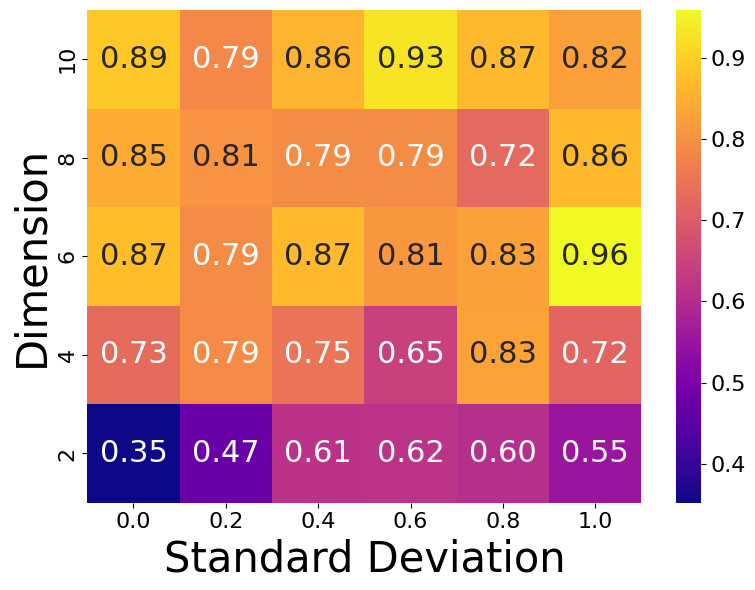

In [10]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["avg_best_benefit_two"].mean().reset_index()

#heatmap_data["avg_best_benefit_two"] = heatmap_data["avg_best_benefit_two"] / 100


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="avg_best_benefit_two")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Standard Deviation", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("expectations_euclidean_avg_best_benefit_two.pdf", format="pdf")
plt.show()


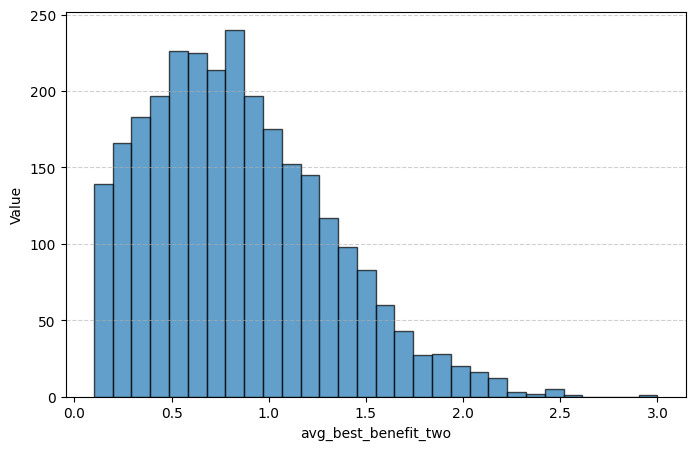

avg_best_benefit_two mean: 0.8211
avg_best_benefit_two median: 0.8000
avg_best_benefit_two max: 3.0000


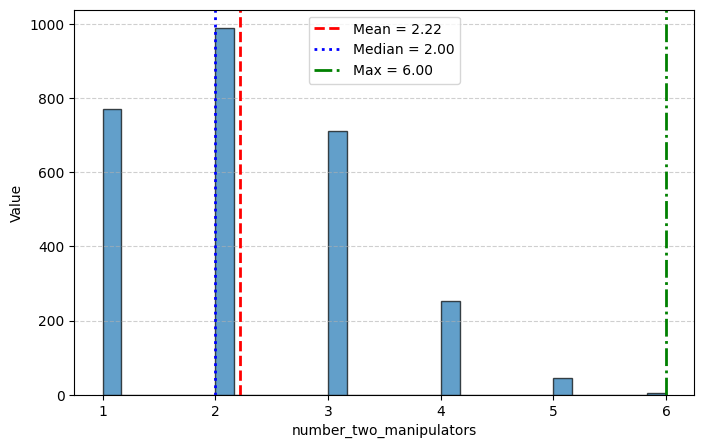

Mean of number_two_manipulators: 2.2169
Median of number_two_manipulators: 2.0000
Max of number_two_manipulators: 6.0000


In [2]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Quick sanity check

#print(df.head())

df = df[df["avg_best_benefit_two"]>0]
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["avg_best_benefit_two"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("avg_best_benefit_two")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["avg_best_benefit_two"].mean()

median_val = df["avg_best_benefit_two"].median()

max_val = df["avg_best_benefit_two"].max()
 
print(f"avg_best_benefit_two mean: {mean_val:.4f}")

print(f"avg_best_benefit_two median: {median_val:.4f}")

print(f"avg_best_benefit_two max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("expectations_euclidean_gain.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["number_two_manipulators"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["number_two_manipulators"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("number_two_manipulators")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["number_two_manipulators"].mean()

median_pos = positive_df["number_two_manipulators"].median()

max_pos = positive_df["number_two_manipulators"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of number_two_manipulators: {mean_pos:.4f}")

print(f"Median of number_two_manipulators: {median_pos:.4f}")

print(f"Max of number_two_manipulators: {max_pos:.4f}")

 

**Fame Euclidean**

In [14]:
df = pd.read_csv("fame_euclidean_gain.csv")

results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matching"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('fame_euclidean_gain.csv', index=False)


2400it [42:01,  1.05s/it]


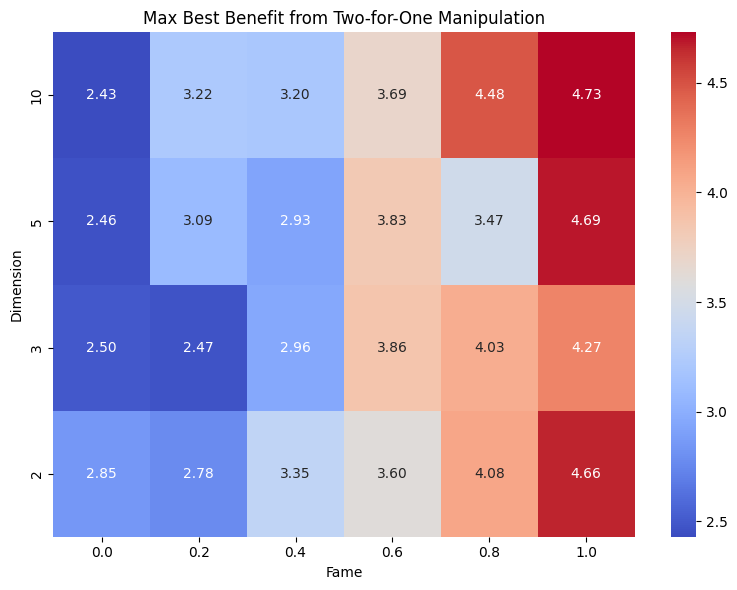

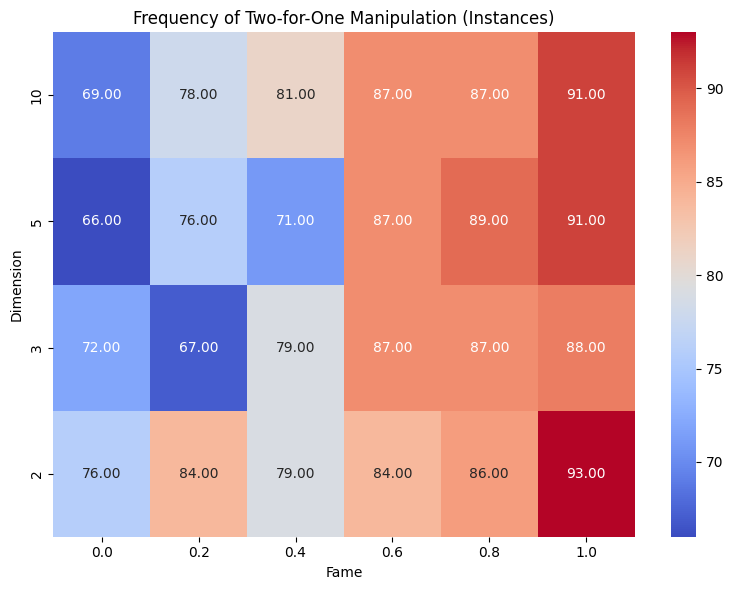

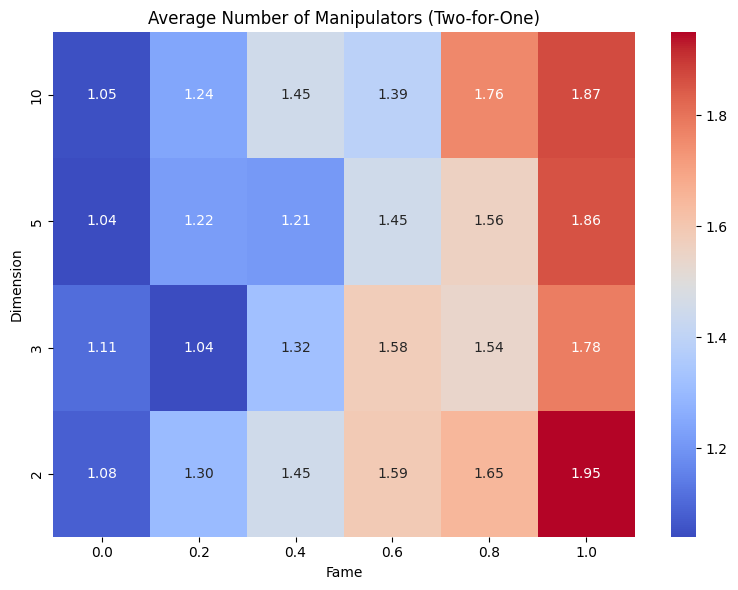

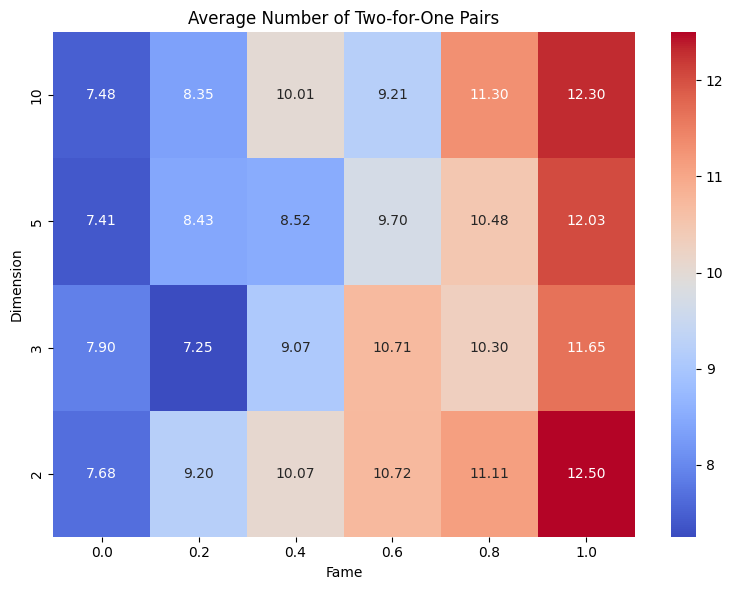

In [44]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import ast  # to convert stringified lists to actual lists

# --- Load your CSV ---
df = pd.read_csv("fame_euclidean_gain.csv")

# Prepare lists to store the new columns
best_benefits_list = []
max_best_benefit_list = []
acc_freq_instance_list = []
number_acc_pairs_list = []
number_acc_manipulators_list = []

for idx, row in df.iterrows():
    # Convert string to list if needed
    two_for_one_results = row["two_for_one_results"]
    if isinstance(two_for_one_results, str):
        two_for_one_results = ast.literal_eval(two_for_one_results)

    # Best benefit per manipulator
    best_benefits_per_woman = [
        max(result[0] for result in manipulator_results)
        for manipulator_results in two_for_one_results
    ]
    best_benefits_list.append(best_benefits_per_woman)

    # Average across manipulators
    max_val = np.max(best_benefits_per_woman) #change np.mean to np.max
    max_best_benefit_list.append(max_val)

    # --- New columns ---
    acc_freq_instance_list.append(1 if max_val > 0 else 0)

    # number_acc_pairs: manipulator has at least one accomplice with benefit > 0
    #num_pairs = sum(
        #any(result[0] > 0 for result in manipulator_results)
        #for manipulator_results in two_for_one_results
    #)
    #number_acc_pairs_list.append(num_pairs)

    num_pairs = sum(
    sum(1 for result in manipulator_results if result[0] > 0)
    for manipulator_results in two_for_one_results
    )
    number_acc_pairs_list.append(num_pairs)

    # number_acc_manipulators: count of >0 best benefits
    num_manipulators = sum(1 for b in best_benefits_per_woman if b > 0)
    number_acc_manipulators_list.append(num_manipulators)

# Add new columns to the original DataFrame
df["best_benefits_per_woman_two"] = best_benefits_list
df["max_best_benefit_two"] = max_best_benefit_list
df["two_freq_instance"] = acc_freq_instance_list
df["number_two_pairs"] = number_acc_pairs_list
df["number_two_manipulators"] = number_acc_manipulators_list

# --- Save the updated DataFrame to CSV ---
df.to_csv("fame_euclidean_gain.csv", index=False)

# --- Function to plot heatmap for a given column ---
def plot_heatmap(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "fame"])[value_col].mean().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="fame",
        values=value_col,
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Fame")
    plt.ylabel("Dimension")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def plot_heatmap_sum(df, value_col, title, filename):
    heatmap_df = df.groupby(["dimension", "fame"])[value_col].sum().reset_index()
    heatmap_matrix = heatmap_df.pivot_table(
        index="dimension",
        columns="fame",
        values=value_col,
        aggfunc="sum"
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title(title)
    plt.xlabel("Fame")
    plt.ylabel("Dimension")
    plt.tight_layout()
    plt.gca().invert_yaxis()

    plt.savefig(f"{filename}.pdf", format="pdf", bbox_inches="tight")
    plt.show()

# --- Generate the 4 plots ---
plot_heatmap(df, "max_best_benefit_two", "Max Best Benefit from Two-for-One Manipulation", "fame_euclidean_max_best_benefit_two")
plot_heatmap_sum(df, "two_freq_instance", "Frequency of Two-for-One Manipulation (Instances)", "fame_euclidean_two_freq_instance")
plot_heatmap(df, "number_two_manipulators", "Average Number of Manipulators (Two-for-One)", "fame_euclidean_number_two_manipulators")
plot_heatmap(df, "number_two_pairs", "Average Number of Two-for-One Pairs", "fame_euclidean_number_two_pairs")


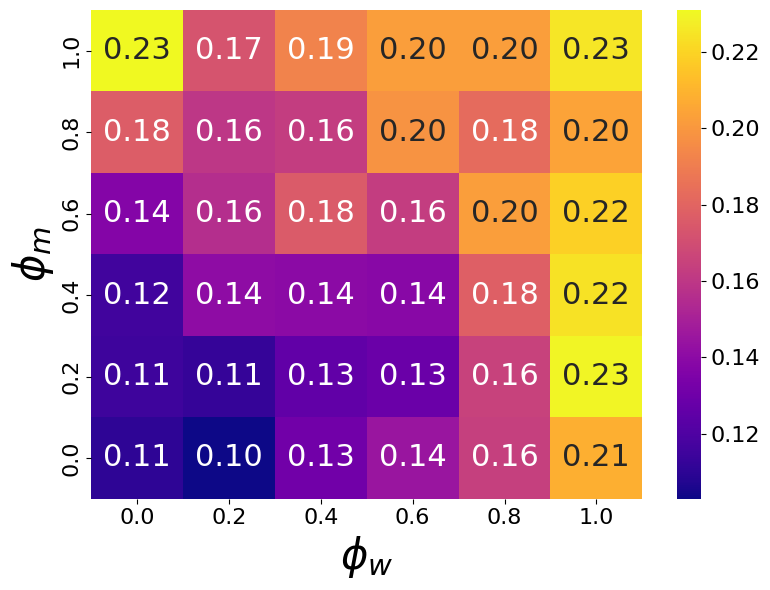

In [39]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_two_manipulators"].mean().reset_index()

heatmap_data["number_two_manipulators"] = heatmap_data["number_two_manipulators"] / 10


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_two_manipulators")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_euclidean_number_two_manipulators.pdf", format="pdf")
plt.show()


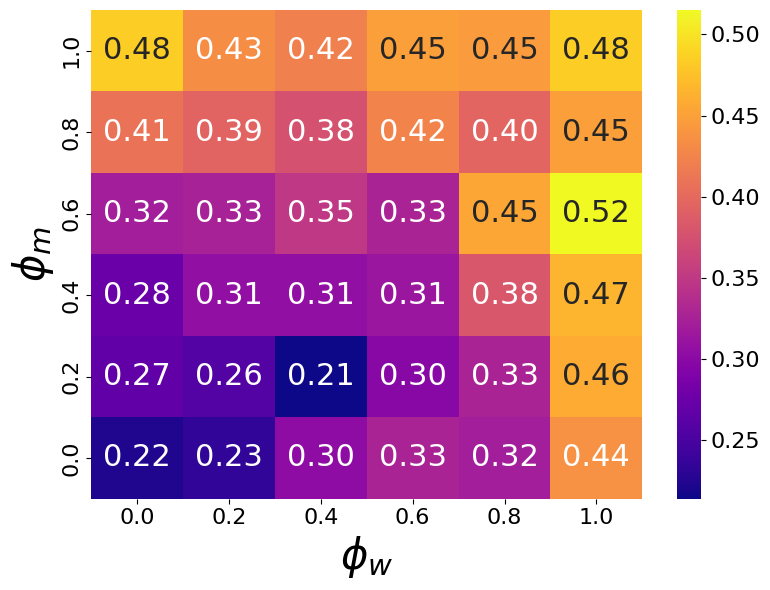

In [11]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["max_best_benefit_two"].mean().reset_index()

heatmap_data["max_best_benefit_two"] = heatmap_data["max_best_benefit_two"] / 10


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="max_best_benefit_two")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_euclidean_max_best_benefit_two.pdf", format="pdf")
plt.show()


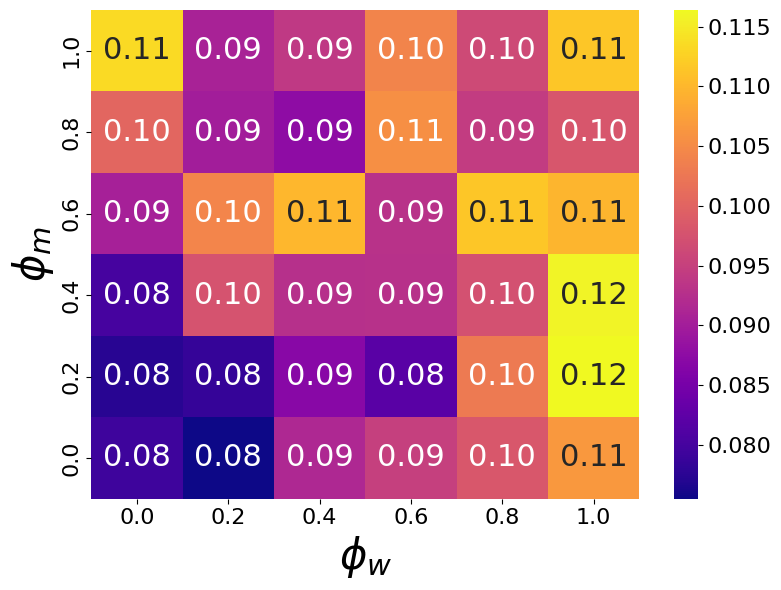

In [40]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_two_pairs"].mean().reset_index()

heatmap_data["number_two_pairs"] = heatmap_data["number_two_pairs"] / 100


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_two_pairs")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("mallows_euclidean_number_two_pairs.pdf", format="pdf")
plt.show()


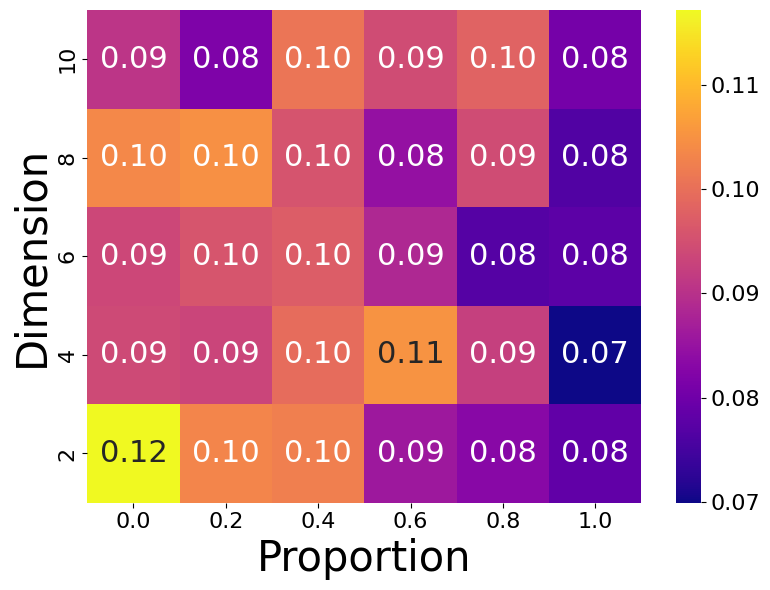

In [42]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("reverse_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "proportion"])["number_two_pairs"].mean().reset_index()

heatmap_data["number_two_pairs"] = heatmap_data["number_two_pairs"] / 100


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="proportion", values="number_two_pairs")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Proportion", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("reverse_euclidean_number_two_pairs.pdf", format="pdf")
plt.show()


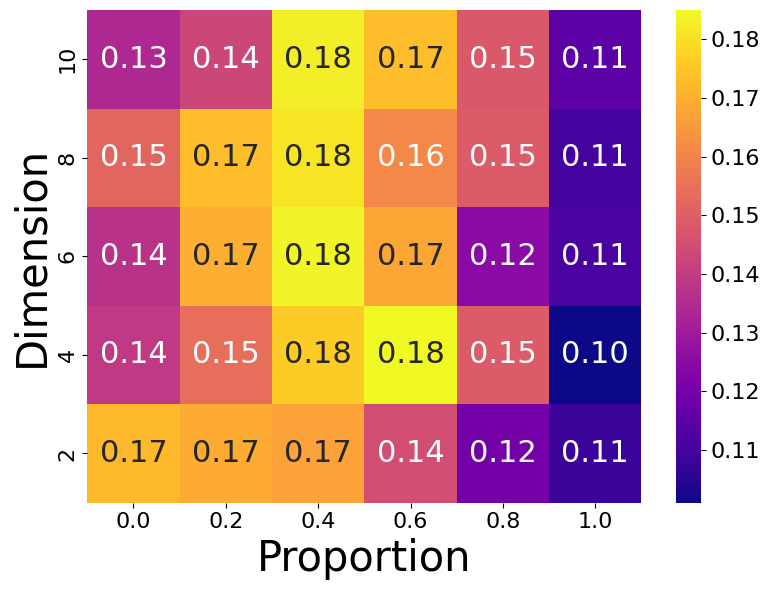

In [12]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("reverse_euclidean_gain.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "proportion"])["number_two_manipulators"].mean().reset_index()

heatmap_data["number_two_manipulators"] = heatmap_data["number_two_manipulators"] / 10 #this is to scale the values down


# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="proportion", values="number_two_manipulators")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Proportion", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("reverse_euclidean_number_two_manipulators.pdf", format="pdf")
plt.show()
